# 4. From microstructure to properties: physics-anchored machine learning

Training data: 80 rows (33 grades x annealed / normalized / hot rolled). Every model is evaluated by
**leave-one-grade-out** cross-validation, so a grade is never seen in training when it is predicted. The
ladder runs from textbook equations, through composition-only ML, to the physics-anchored models.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
b = pd.read_csv(R / "s04_model_benchmark.csv")
b.pivot(index="model", columns="target", values="RMSE_inAD").round(1)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,3.5,17.5,58.8,47.2
anchored_gp,3.5,17.5,58.8,51.9
gated_ensemble,2.7,13.7,52.5,42
gbm_comp,3.1,24.6,86.8,62.1
gp_comp,2.5,22.4,58.5,54.7
gp_hybrid,2.6,17.6,50.6,48.7
gp_phys,2.7,16.8,59.1,51.7
greybox,4.3,26.2,88.7,56.4
greybox_gp,3.2,20.5,65.3,53.6


In [3]:
b.pivot(index="model", columns="target", values="R2_inAD").round(3)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,0.733,0.901,0.908,0.841
anchored_gp,0.733,0.901,0.908,0.808
gated_ensemble,0.835,0.94,0.926,0.874
gbm_comp,0.787,0.806,0.799,0.725
gp_comp,0.866,0.838,0.909,0.787
gp_hybrid,0.849,0.901,0.932,0.83
gp_phys,0.837,0.91,0.907,0.809
greybox,0.593,0.779,0.79,0.773
greybox_gp,0.777,0.866,0.886,0.794


Accuracy on the **change** from annealed to normalized - the what-if this project is about:

In [4]:
b.pivot(index="model", columns="target", values="delta_RMSE").round(1)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,4,24.5,77.7,55
anchored_gp,4,24.5,77.7,53.2
gated_ensemble,3.2,16.6,74.3,50.5
gbm_comp,3.6,27.8,99.5,69.8
gp_comp,3.1,23.7,72.7,63.3
gp_hybrid,3.2,19.7,73.5,63.7
gp_phys,3.3,23.1,84.2,67.2
greybox,4.7,27.2,93.9,50.4
greybox_gp,3.7,26.7,87.6,54.7


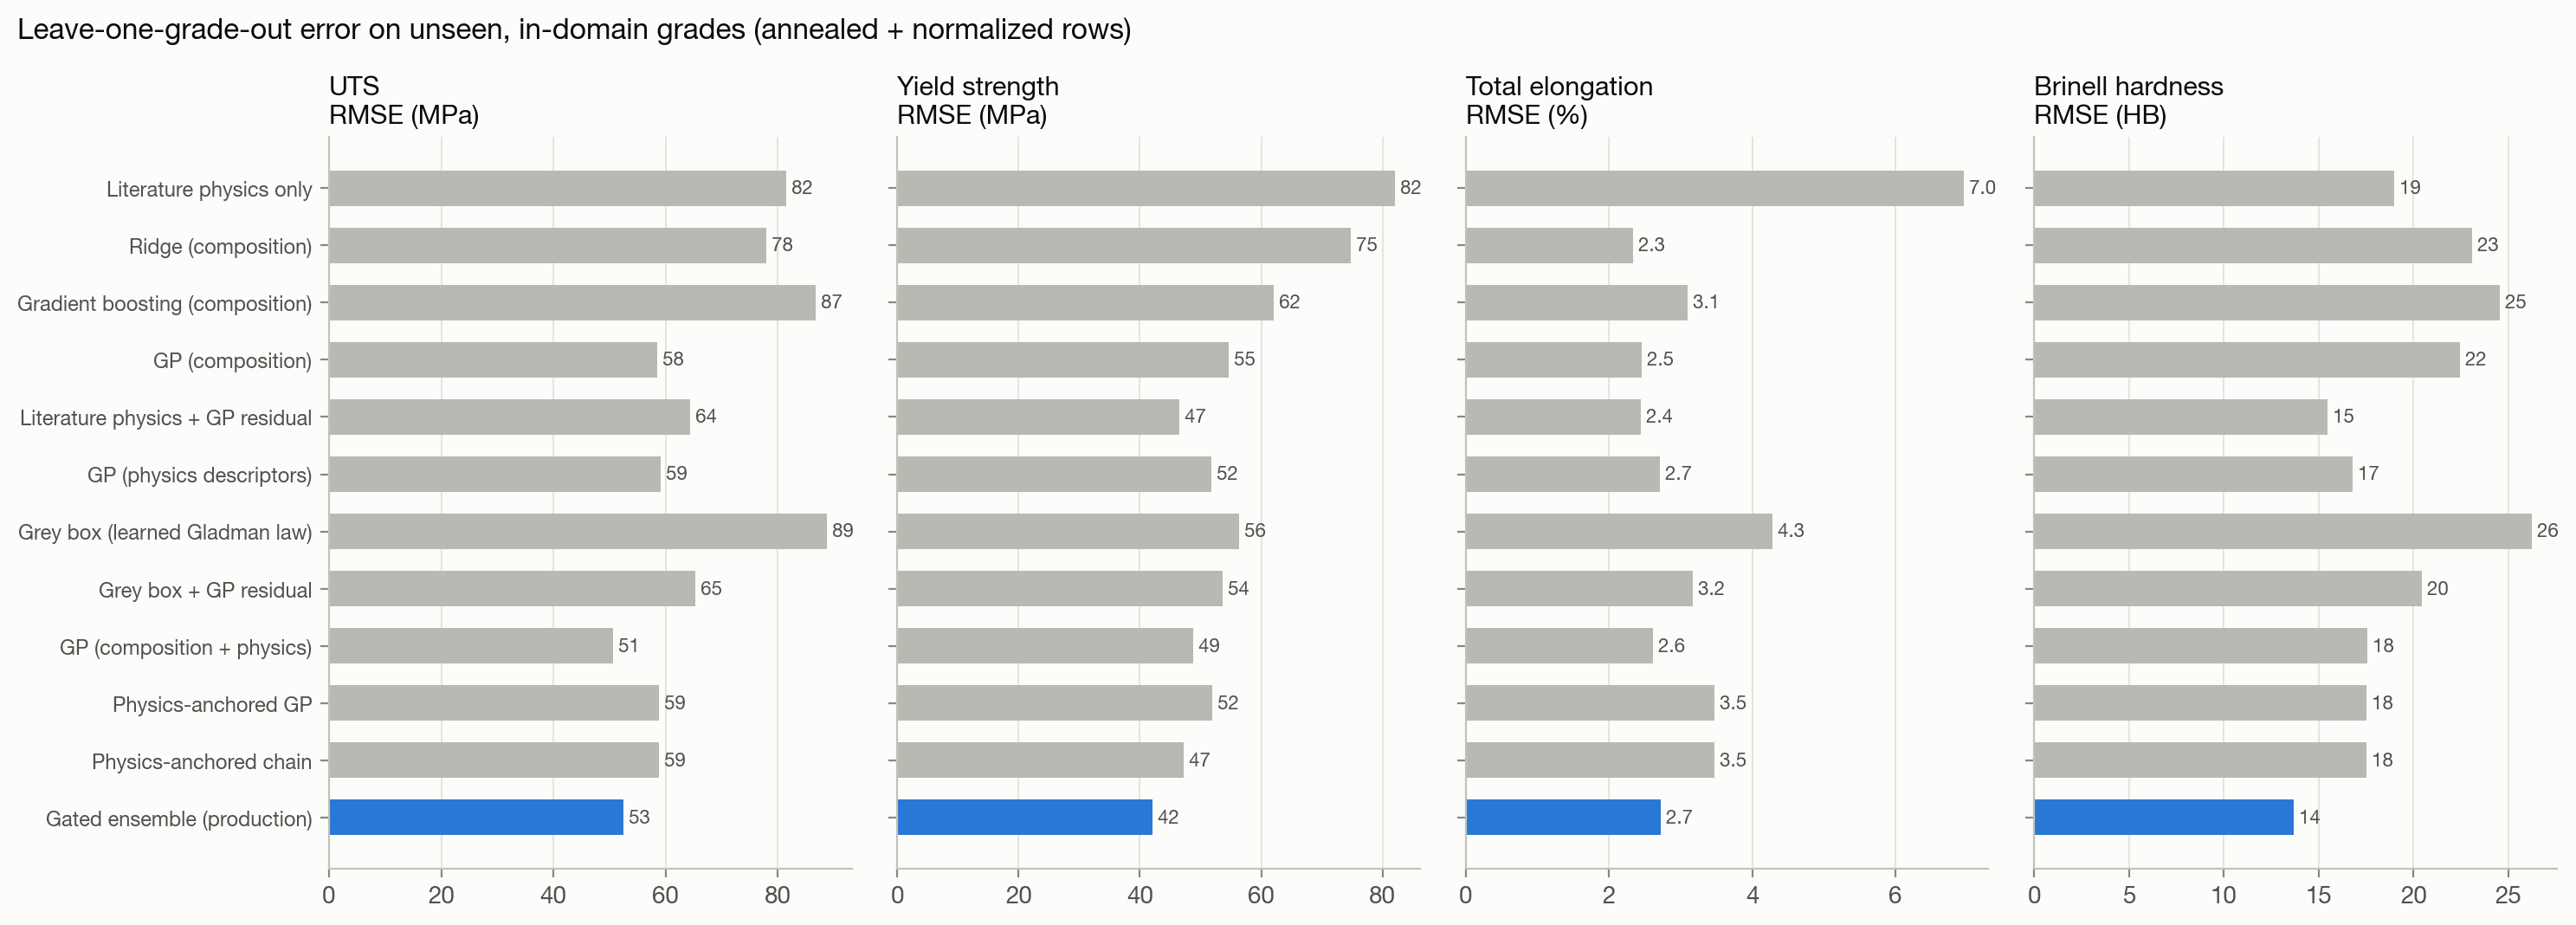

In [5]:
fig("fig12_model_ladder")

## Are the differences real? Paired tests against the production model
Per-grade errors, Wilcoxon signed-rank test (with the Holm adjustment for the eleven comparisons per property)
and a bootstrap 95 % interval of the RMSE difference (positive = the other model is worse).

In [6]:
pd.read_csv(R / "s04_paired_tests.csv").round(3)

,target,model,RMSE_minus_production,CI95_lo,CI95_hi,wilcoxon_p,n_grades,wilcoxon_p_holm
0,UTS_MPa,physics_lit,29,14.1,44.4,0.001,27,0.006
1,UTS_MPa,ridge_comp,25.5,3.78,44.2,0.026,27,0.157
2,UTS_MPa,gbm_comp,34.2,10.5,55.5,0.02,27,0.14
3,UTS_MPa,gp_comp,5.93,-9.98,22.5,0.578,27,1
4,UTS_MPa,physlit_gp,11.9,4.44,18.4,0.009,27,0.071
5,UTS_MPa,gp_phys,6.54,-6.67,18.9,0.155,27,0.465
6,UTS_MPa,greybox,36.2,24.2,48.8,0,27,0.001
7,UTS_MPa,greybox_gp,12.8,7.7,18.5,0,27,0.001
8,UTS_MPa,gp_hybrid,-1.94,-11.1,7.27,0.915,27,1
9,UTS_MPa,anchored_gp,6.26,1.38,11.2,0.073,27,0.366


## Uncertainty: normalised conformal intervals
The ensemble's own error bars are only roughly calibrated (a Gaussian 90 % interval would use 1.645 standard
deviations; the factors below range from about 1.5 to 2.1). Normalised split-conformal calibration rescales them
so that the intervals cover 90 % of unseen grades, and that coverage is checked here.

In [7]:
pd.read_csv(R / "s04_conformal.csv")

,target,q90_normalised,LOGO_coverage_90,mean_interval_width
0,UTS_MPa,1.64,0.91,164
1,YS_MPa,1.37,0.925,124
2,El_pct,2.27,0.925,8.85
3,HB,1.34,0.925,45.9


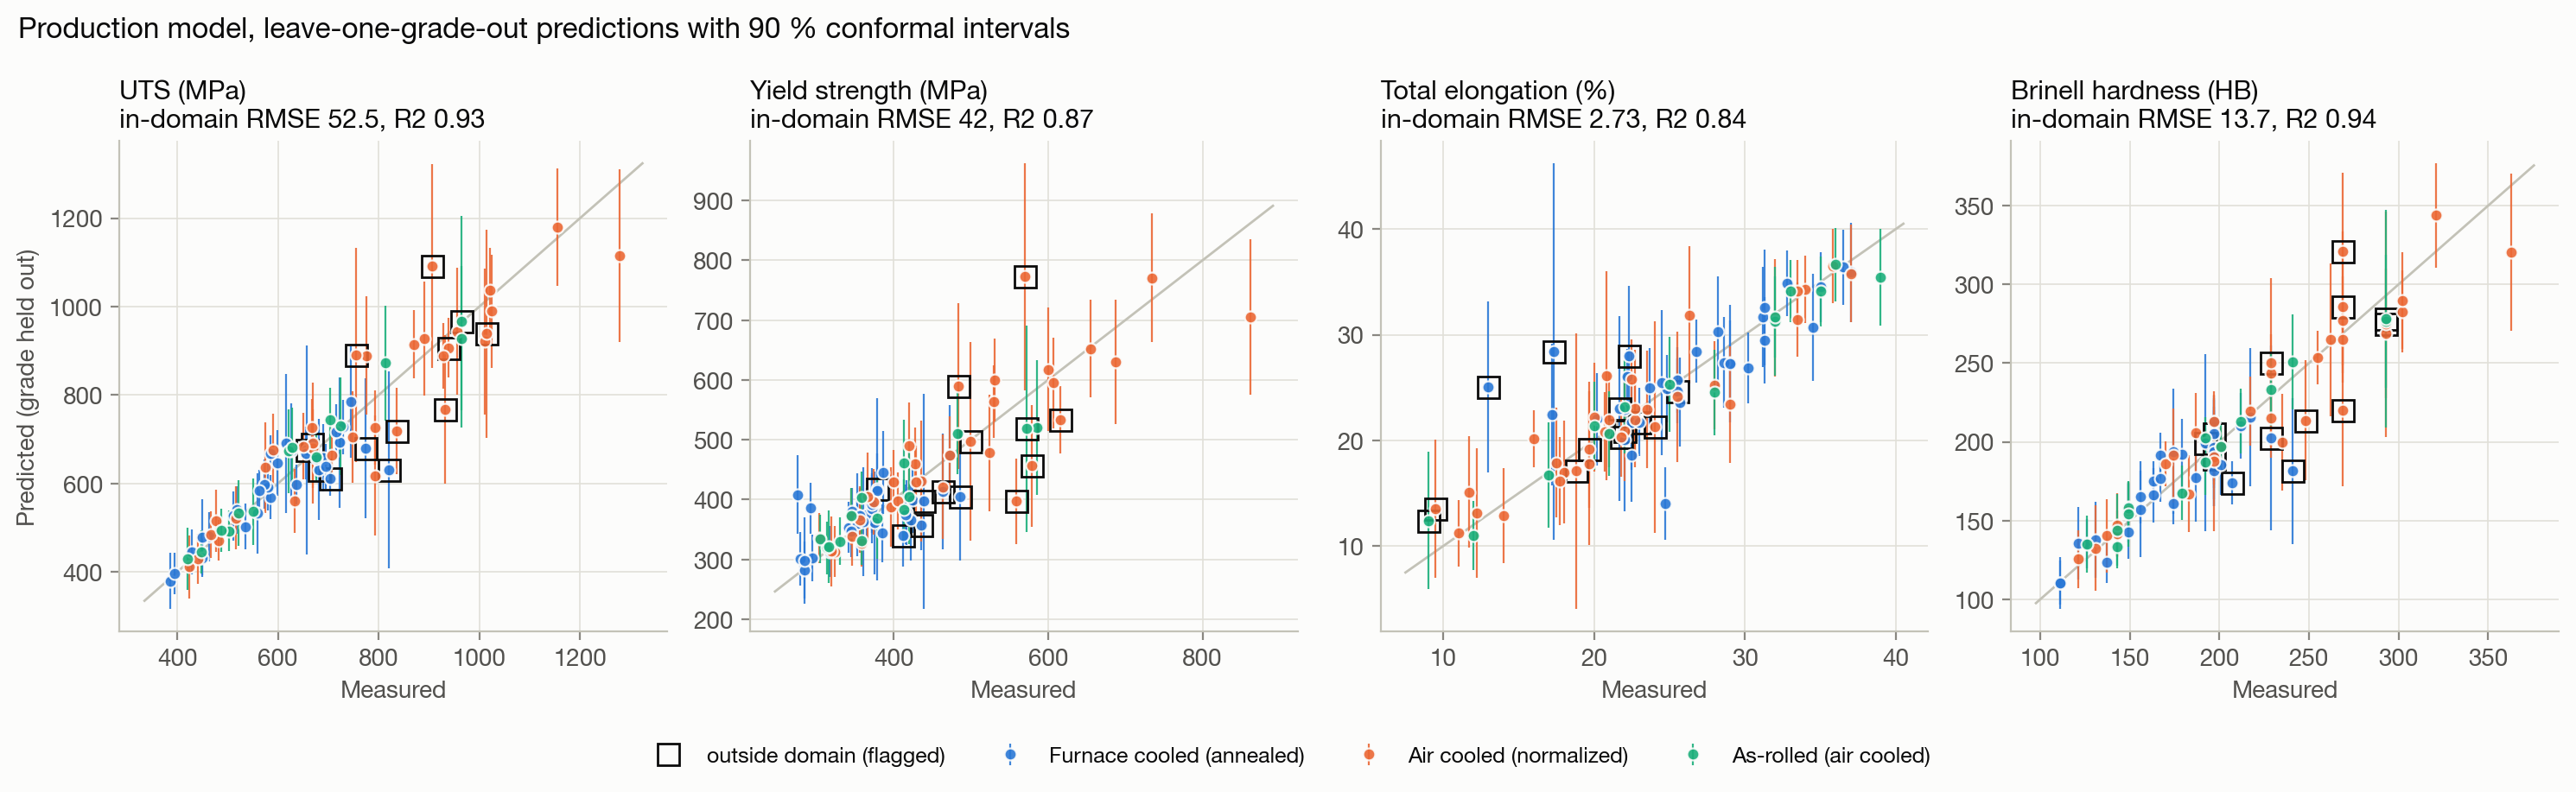

In [8]:
fig("fig13_parity_production")

## The decisive test: cooling rates the training data never contain
Models trained only on annealed/normalised data predict the measured hardness of three steels cooled at
0.1-50 K/s. ML without physics cannot invent the hardness of bainite or martensite; the physics-anchored
production model inherits it from the transformation model.

In [9]:
pd.read_csv(R / "s04_cooling_rate_extrapolation.csv").round(1)

,model,HB_RMSE_EN3B,HB_RMSE_EN8,HB_RMSE_SA540,HB_RMSE_rates_le_5Ks,HB_RMSE_all
0,physics_lit,23.9,77.5,85.6,56.8,68.1
1,ridge_comp,15.5,21.5,251,133,146
2,gbm_comp,35.4,41,271,140,160
3,gp_comp,17.5,27,204,95.4,119
4,physlit_gp,23.2,77.1,74,48,63.1
5,gp_phys,13.6,20.5,230,108,134
6,greybox,24.7,75.7,112,71.3,79.1
7,greybox_gp,12.7,83.8,95.7,58.8,73.8
8,gp_hybrid,15.6,11.6,226,107,131
9,anchored_gp,10.4,84.7,52.3,38.1,57.8


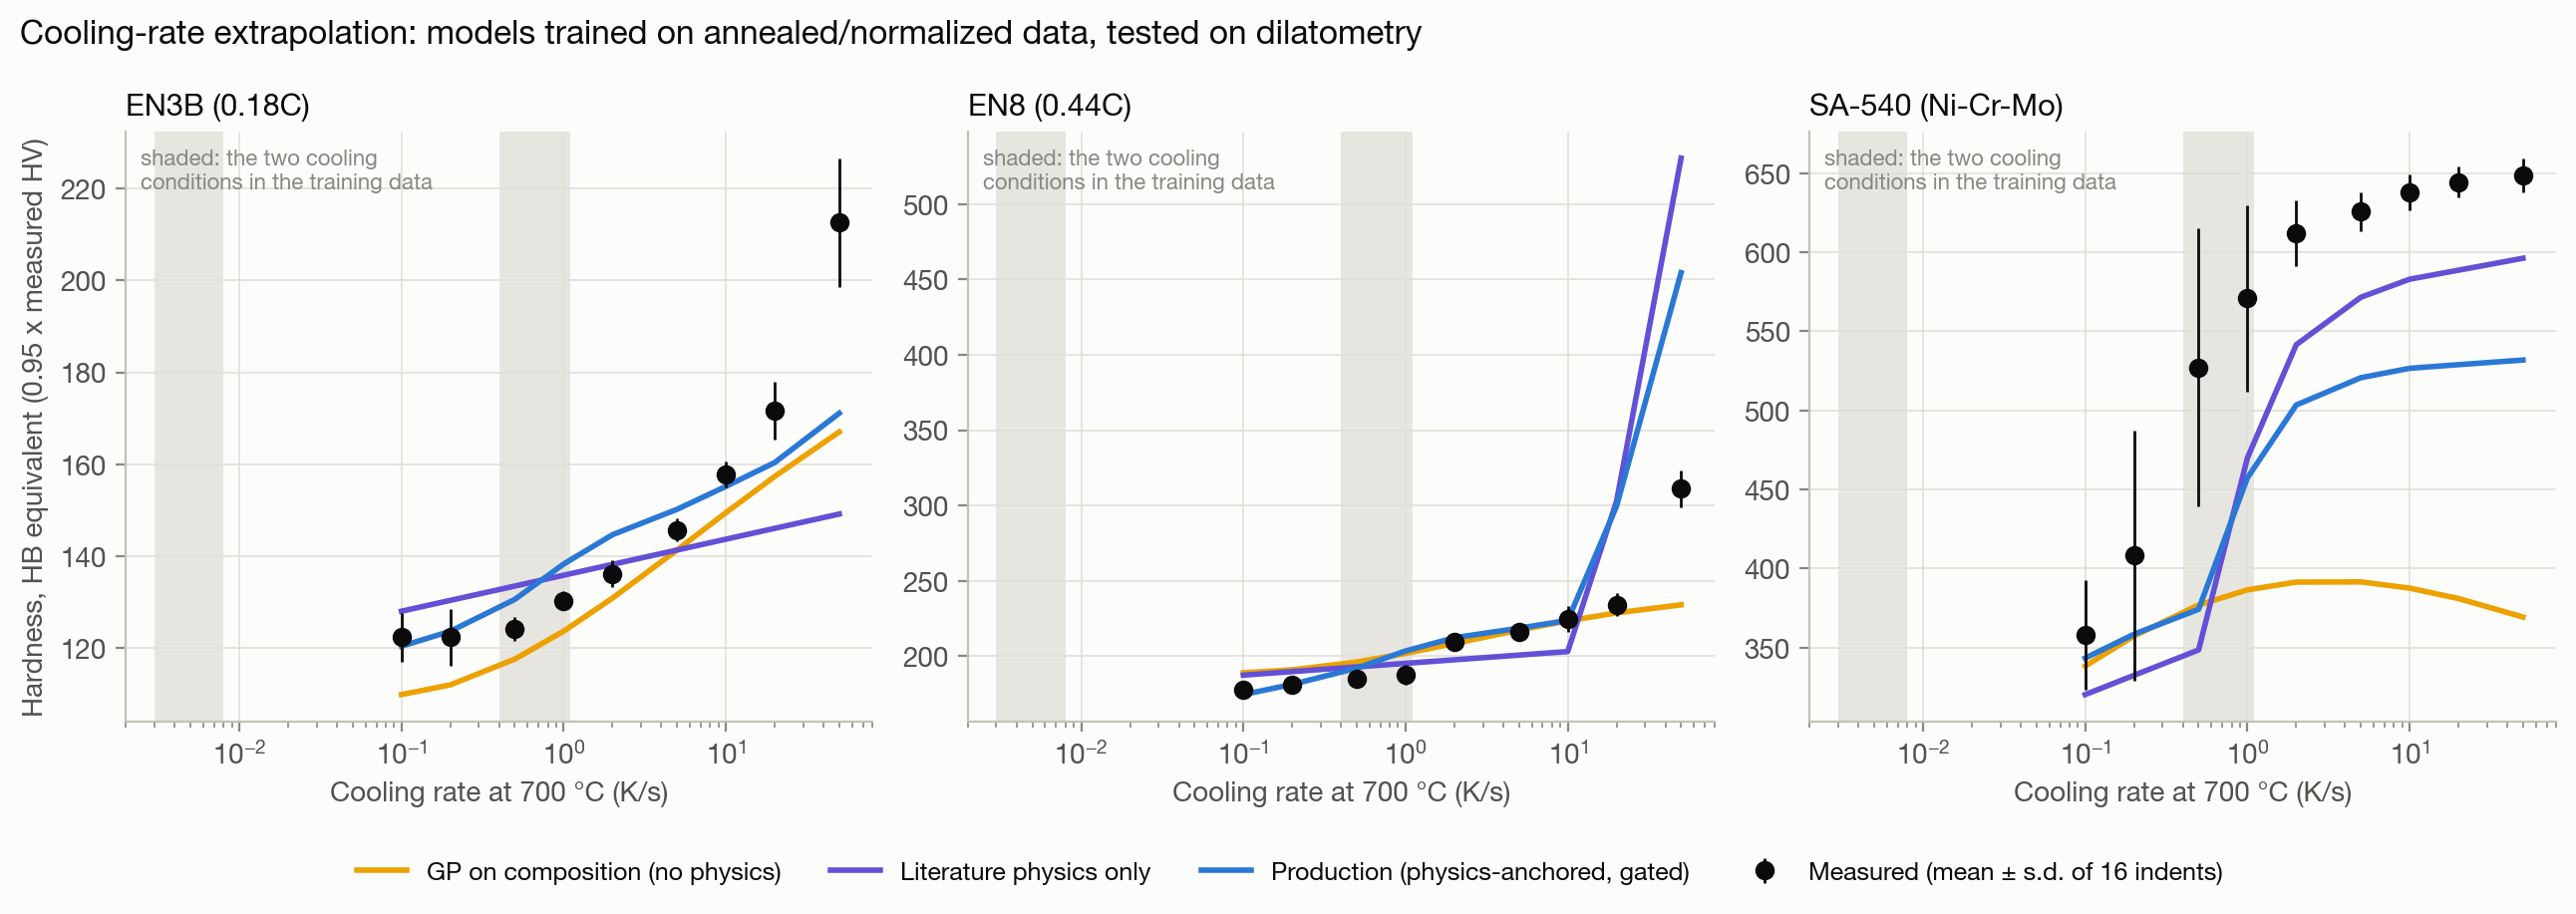

In [10]:
fig("fig14_cooling_rate_extrapolation")

## Physical consistency and interpretability
Share of cooling-rate steps where a property moves the wrong way, and the span of the predicted UTS / HB
over a normal 0.10-0.40 % Si (physically a few tens of MPa).

In [11]:
c = pd.read_csv(R / "s04_consistency.csv")
c.pivot(index="model", columns="target", values="rate_violation_frac").round(3)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,0.051,0.008,0.043,0.058
anchored_gp,0.051,0.008,0.043,0.028
gated_ensemble,0.01,0.01,0.015,0.005
gbm_comp,0,0,0,0
gp_comp,0,0,0,0
gp_hybrid,0.005,0.005,0.018,0
gp_phys,0.013,0,0,0.033
greybox,0.003,0.008,0.008,0.008
greybox_gp,0.061,0.035,0.028,0.015


In [12]:
c.pivot(index="model", columns="target", values="si_0.10_0.40_span").round(1)

target,El_pct,HB,UTS_MPa,YS_MPa
model,,,,
anchored_chain,1,8.6,37.4,28.7
anchored_gp,1,8.6,37.4,23.7
gated_ensemble,0.3,6.1,22.6,17
gbm_comp,0.2,4.1,9.9,27.3
gp_comp,0,2.3,14.2,1.7
gp_hybrid,0.1,1.7,13.8,3.9
gp_phys,0.4,4.4,22.6,31.7
greybox,0.6,7.9,26.5,19.8
greybox_gp,0.8,8.1,26.7,19.2


## Two lessons, kept as ablations
**Silicon.** Every training grade has the same nominal Si (0.225 % carbon grades, 0.25 % alloy H-grades)
except 9255. With Si as an input, cross-validation looks better because Si labels the grade type, but the
response to a real change of Si is unphysical. Si and V are therefore left to the physics.

In [13]:
pd.read_csv(R / "s04_silicon_ablation.csv").round(1)

,silicon_input,model,UTS_RMSE_inAD,UTS_RMSE_outAD,UTS_span_Si_0.10_to_0.40
0,False,gp_comp,58.5,87.1,14.2
1,False,gated_ensemble,52.5,114,22.6
2,True,gp_comp,54.5,98.8,27.1
3,True,gated_ensemble,54.8,117,217


**The gate.** Handing over to the physics-anchored members for every unfamiliar composition, or above
the fastest training cooling rate, was tried first; this table re-scores those rules on the same evidence.

In [14]:
pd.read_csv(R / "s04_gate_ablation.csv").set_index("rule").T.round(3)

rule,final: hard phase + martensite,final + composition gate,final + cooling-rate gate,first version: composition + rate + hard phase
UTS_MPa_RMSE_outAD,114,111,114,111
UTS_MPa_RMSE_inAD,52.5,52.5,52.5,52.5
UTS_MPa_check_vs_production,0,NaN,NaN,NaN
YS_MPa_RMSE_outAD,101,96.7,101,96.7
YS_MPa_RMSE_inAD,42,42,42,42
YS_MPa_check_vs_production,0,NaN,NaN,NaN
El_pct_RMSE_outAD,5.28,5.58,5.28,5.58
El_pct_RMSE_inAD,2.73,2.73,2.73,2.73
El_pct_check_vs_production,0,NaN,NaN,NaN
HB_RMSE_outAD,32.8,33.2,32.8,33.2


**The physics anchor.** The anchored models first scaled every property on the Maynier hardness, whose
ferrite-pearlite term depends on composition and cooling rate only and cannot see pearlite refinement. They
now scale on the Gladman law (ferrite fraction, grain size, spacing) for ferrite + pearlite and on Maynier
for bainite and martensite. Inside the data this costs a few MPa; at new cooling rates and for new
compositions it is clearly better.

In [15]:
pd.read_csv(R / "s04_anchor_ablation.csv").set_index("anchor").T.round(3)

anchor,"Maynier hardness, all constituents (first version)","Gladman law for F+P, Maynier for B+M (production)"
UTS_MPa_RMSE_inAD,48.9,52.5
UTS_MPa_RMSE_outAD,119,114
UTS_MPa_change_RMSE,66.4,74.3
YS_MPa_RMSE_inAD,38.5,42
YS_MPa_RMSE_outAD,99.5,101
YS_MPa_change_RMSE,49.9,50.5
El_pct_RMSE_inAD,2.41,2.73
El_pct_RMSE_outAD,4.62,5.28
El_pct_change_RMSE,2.75,3.21
HB_RMSE_inAD,14.3,13.7


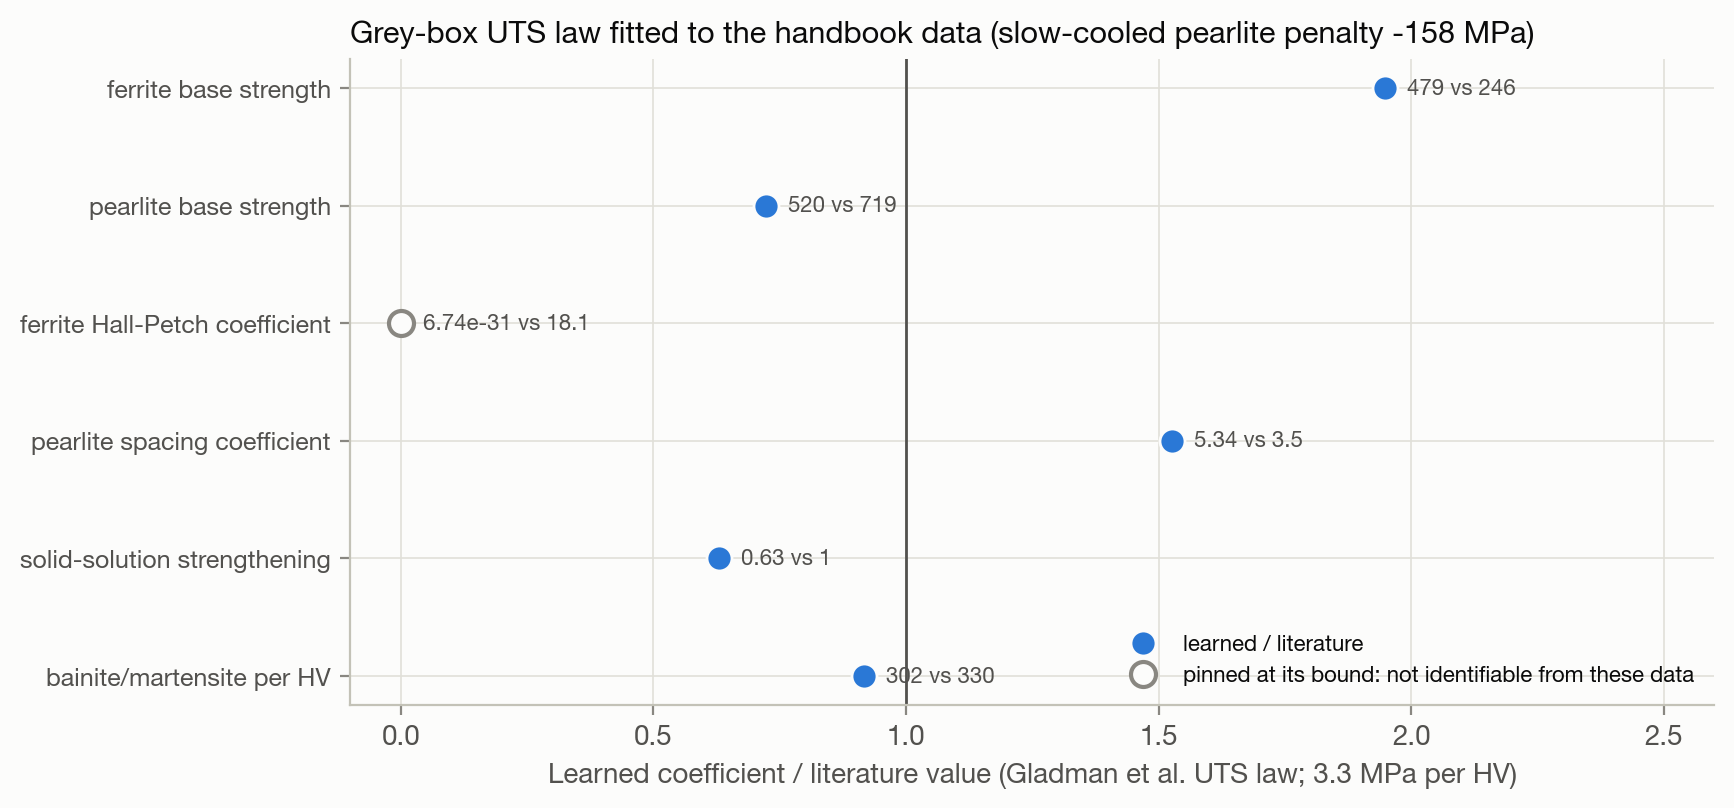

In [16]:
fig("fig15_greybox_coefficients", 800)